This notebook should help to understand and show/proof the hypothesis "With more cells in a dataset we have a higher wasserstein distance".  Higher waserstein distance can occure through
1. Cosine similarity of the upper bound increases closer to 1 with an increasing number of cell and the 2D test optimal velocity stays
2. Cosine similarity of the upper bound increases closer to 1 with an increasing number of cell and the 2D test optimal velocity decreases
3. Cosine similarity of the upper bound increases closer to 1 with an increasing number of cell and the 2D test optimal velocity increases, but slower
4. Cosine similarity of the upper bound is not influenced by the cell number and the 2D test optimal velocity decreases with an increasing cell number

Futher there is the idea that it also depends on the level of dimension for the upper bound as due to the curse of dimensionalty a lot of vectors have a cosine similarity of 0 and are othogonal. 
This should be tested experimentally and maybe on paper be prooven mathemativally

In [2]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import gaussian_kde
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import math
import random
from scipy.stats import cumfreq
import yaml
import scanpy as sc
from scipy.stats import vonmises
import torch
from tqdm import tqdm
import scvelo
from velotest.neighbors import find_neighbors

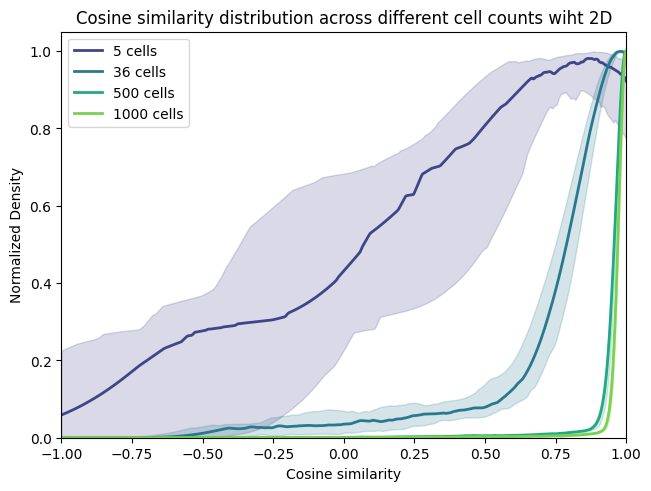

In [ ]:
# Start with a 2D embedding 
# 0) Rewrite everything an loops for easier computation
number_cells = [5, 36, 500, 1000]
rng = np.random.default_rng()
repeats = 50

save_max_data = []

for run in range(repeats):
    for i, cells in enumerate(number_cells):
        # 1) Create a random number of cells in 2D space
        expression_space = rng.random((cells, 2)) # random() for uniform distribution (might not be correct, maybe improve to a von-misses distribution...)

        # 2) Create a raondom velocity-vector for each cell in 2D space
        velocity_vectors = rng.standard_normal((cells, 2)) # standard_normal() (That is what Sebastian suggested in his mail and was easier for me to understand than his code...)
        # TODO: Check if this work in one step (i.g. 2 layers of random numbers) and if normalization is needed

        # 3) Compute maximum cosine similarity for each cell 
        # TODO: Adapt this for neighbor cells maybe
        maxs = []
        for j in range(cells):
            expression_difference = expression_space - expression_space[j]
            cosine_sim = cosine_similarity(velocity_vectors[j].reshape(1, -1), expression_difference)
            cosine_sim[0, j] = -1 # To ignore self-comparison which is 0
            maxs.append(np.max(cosine_sim))
        # Save data
            save_max_data.append({
                "Repeat": run,
                "Cells": cells,
                "Cosine similarity": np.max(cosine_sim)
            })

# 4) Plot change in cosine similarity with increasing number of cells
df = pd.DataFrame(save_max_data)

_, ax = plt.subplots(constrained_layout=True)
palette = sns.color_palette("viridis", len(number_cells))
x_grid = np.linspace(-1, 1, 500)

for color, cells in zip(palette, number_cells):
    # Calculate KDE for each repeat
    repeat_kdes = []
    for run in range(repeats):
        values = df.loc[
            (df["Cells"] == cells) &
            (df["Repeat"] == run),
            "Cosine similarity"
        ]

        kde = gaussian_kde(values)
        y = kde(x_grid)
        # Normalize peak to 1
        y /= y.max()
        repeat_kdes.append(y)

    repeat_kdes = np.asarray(repeat_kdes)

    # Median curve
    median = np.median(repeat_kdes, axis=0)
    # Variability band
    q25 = np.percentile(repeat_kdes, 25, axis=0)
    q75 = np.percentile(repeat_kdes, 75, axis=0)

    ax.plot(x_grid,
            median,
            color=color,
            lw=2,
            label=f"{cells} cells")

    ax.fill_between(x_grid,
                    q25,
                    q75,
                    color=color,
                    alpha=0.2)

ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Normalized Density")
ax.legend()
ax.set_xlim(-1,1)
ax.set_ylim(0,1.05)
ax.set_title("Cosine similarity distribution across different cell counts wiht 2D")
plt.show()


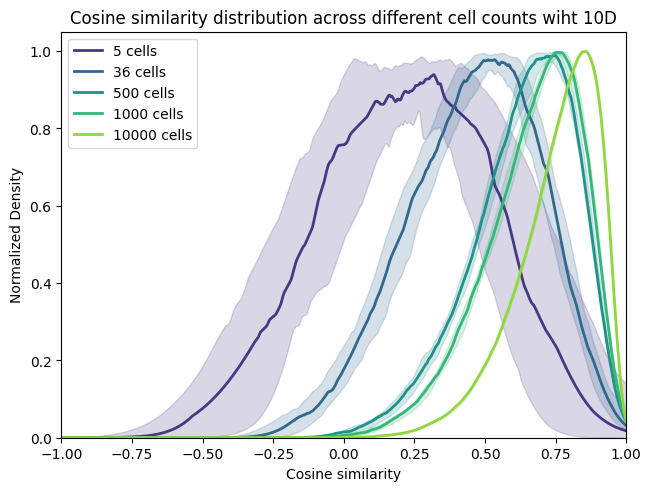

In [ ]:
# Increase dimesionality to 10D
# 0) Rewrite everything an loops for easier computation
number_cells = [5, 36, 500, 1000, 10000]
rng = np.random.default_rng()
repeats = 50

save_max_data = []

for run in range(repeats):
    for i, cells in enumerate(number_cells):
        # 1) Create a random number of cells in 10D space
        expression_space = rng.random((cells, 10)) # standard_normal() for gaussian or random() for uniform distribution

        # 2) Create a raondom velocity-vector for each cell in 10D space
        velocity_vectors = rng.standard_normal((cells, 10)) # standard_normal() for gaussian or random() for uniform distribution
        # TODO: Check if this work in one step (i.g. 2 layers of random numbers) and if normalization is needed

        # 3) Compute maximum cosine similarity for each cell 
        # TODO: Adapt this for neighbor cells maybe
        maxs = []
        for j in range(cells):
            expression_difference = expression_space - expression_space[j]
            cosine_sim = cosine_similarity(velocity_vectors[j].reshape(1, -1), expression_difference)
            cosine_sim[0, j] = -1 # To ignore self-comparison which is 0
            maxs.append(np.max(cosine_sim))
        # Save data
            save_max_data.append({
                "Repeat": run,
                "Cells": cells,
                "Cosine similarity": np.max(cosine_sim)
            })

# 4) Plot change in cosine similarity with increasing number of cells
df = pd.DataFrame(save_max_data)

_, ax = plt.subplots(constrained_layout=True)
palette = sns.color_palette("viridis", len(number_cells))
x_grid = np.linspace(-1, 1, 500)

for color, cells in zip(palette, number_cells):
    # Calculate KDE for each repeat
    repeat_kdes = []
    for run in range(repeats):
        values = df.loc[
            (df["Cells"] == cells) &
            (df["Repeat"] == run),
            "Cosine similarity"
        ]

        kde = gaussian_kde(values)
        y = kde(x_grid)
        # Normalize peak to 1
        y /= y.max()
        repeat_kdes.append(y)

    repeat_kdes = np.asarray(repeat_kdes)

    # Median curve
    median = np.median(repeat_kdes, axis=0)
    # Variability band
    q25 = np.percentile(repeat_kdes, 25, axis=0)
    q75 = np.percentile(repeat_kdes, 75, axis=0)

    ax.plot(x_grid,
            median,
            color=color,
            lw=2,
            label=f"{cells} cells")

    ax.fill_between(x_grid,
                    q25,
                    q75,
                    color=color,
                    alpha=0.2)

ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Normalized Density")
ax.legend()
ax.set_xlim(-1,1)
ax.set_ylim(0,1.05)
ax.set_title("Cosine similarity distribution across different cell counts wiht 10D")
plt.show()


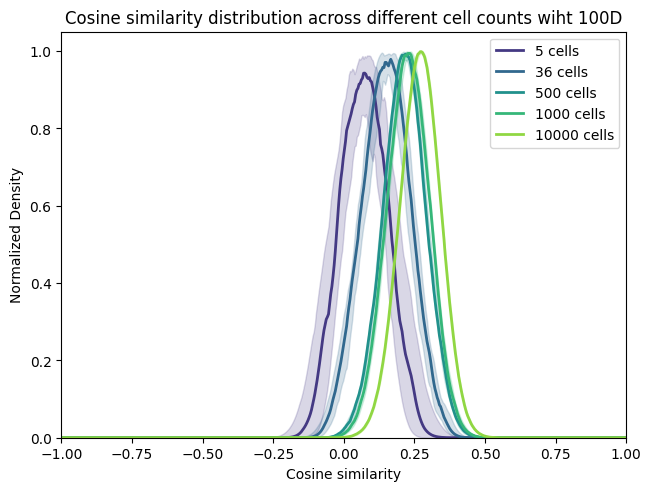

In [ ]:
# And to 100D
# 0) Rewrite everything an loops for easier computation
number_cells = [5, 36, 500, 1000, 10000]
rng = np.random.default_rng()
repeats = 50

save_max_data = []

for run in range(repeats):
    for i, cells in enumerate(number_cells):
        # 1) Create a random number of cells in 100D space
        expression_space = rng.random((cells, 100)) # standard_normal() for gaussian or random() for uniform distribution

        # 2) Create a raondom velocity-vector for each cell in 100D space
        velocity_vectors = rng.standard_normal((cells, 100)) # standard_normal() for gaussian or random() for uniform distribution
        # TODO: Check if this work in one step (i.g. 2 layers of random numbers) and if normalization is needed

        # 3) Compute maximum cosine similarity for each cell 
        # TODO: Adapt this for neighbor cells maybe
        maxs = []
        for j in range(cells):
            expression_difference = expression_space - expression_space[j]
            cosine_sim = cosine_similarity(velocity_vectors[j].reshape(1, -1), expression_difference)
            cosine_sim[0, j] = -1 # To ignore self-comparison which is 0
            maxs.append(np.max(cosine_sim))
        # Save data
            save_max_data.append({
                "Repeat": run,
                "Cells": cells,
                "Cosine similarity": np.max(cosine_sim)
            })

# 4) Plot change in cosine similarity with increasing number of cells
df = pd.DataFrame(save_max_data)

_, ax = plt.subplots(constrained_layout=True)
palette = sns.color_palette("viridis", len(number_cells))
x_grid = np.linspace(-1, 1, 500)

for color, cells in zip(palette, number_cells):
    # Calculate KDE for each repeat
    repeat_kdes = []
    for run in range(repeats):
        values = df.loc[
            (df["Cells"] == cells) &
            (df["Repeat"] == run),
            "Cosine similarity"
        ]

        kde = gaussian_kde(values)
        y = kde(x_grid)
        # Normalize peak to 1
        y /= y.max()
        repeat_kdes.append(y)

    repeat_kdes = np.asarray(repeat_kdes)

    # Median curve
    median = np.median(repeat_kdes, axis=0)
    # Variability band
    q25 = np.percentile(repeat_kdes, 25, axis=0)
    q75 = np.percentile(repeat_kdes, 75, axis=0)

    ax.plot(x_grid,
            median,
            color=color,
            lw=2,
            label=f"{cells} cells")

    ax.fill_between(x_grid,
                    q25,
                    q75,
                    color=color,
                    alpha=0.2)

ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Normalized Density")
ax.legend()
ax.set_xlim(-1,1)
ax.set_ylim(0,1.05)
ax.set_title("Cosine similarity distribution across different cell counts wiht 100D")
plt.show()


I added this code later following the explanation from https://sungwon-kim.com/blog/2025/random-cosine-similarity/

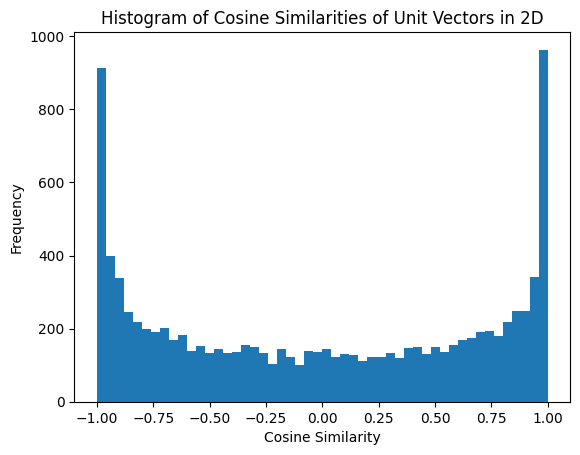

In [ ]:

def get_random_point_on_circle():
    angle = random.uniform(0, 2 * math.pi) # This code is similar to Sebastian implementation
    x = math.cos(angle)
    y = math.sin(angle)
    return (x, y)

random_points = [get_random_point_on_circle() for _ in range(10000)]

first_item = random_points[0]
cosine_similarities = []
for i in range(1, len(random_points)):
    dot_product = first_item[0] * random_points[i][0] + first_item[1] * random_points[i][1]
    cosine_similarities.append(dot_product)

plt.hist(cosine_similarities, bins=50)
plt.title("Histogram of Cosine Similarities of Unit Vectors in 2D")
plt.xlabel("Cosine Similarity")
plt.ylabel("Frequency")
plt.show()

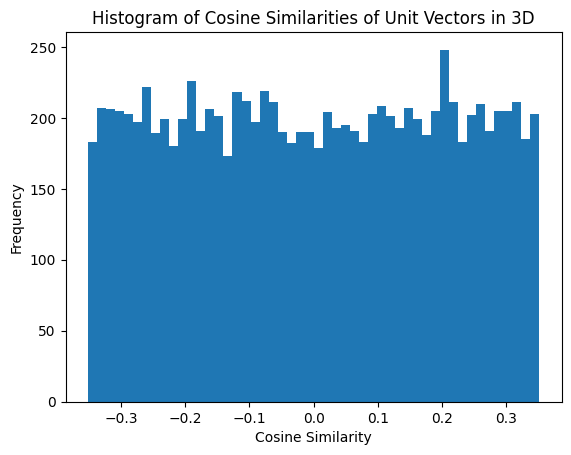

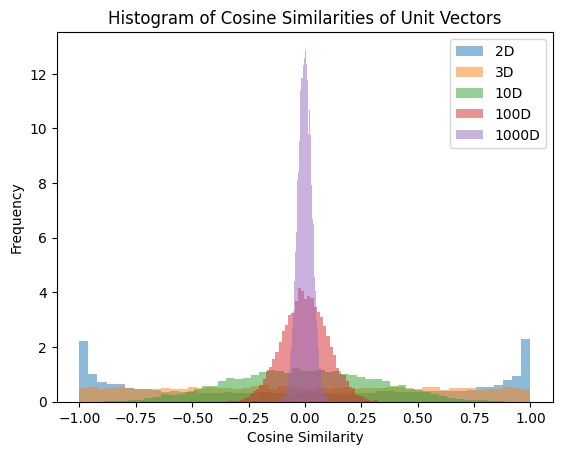

In [19]:
def random_point_on_unit_sphere(n: int) -> np.ndarray:
    point = np.random.randn(n) # Not really sure if that sampling is correct, but as the previous sampling for 2D was the same Sebastian did I trust the website for now. 
    point = point / np.linalg.norm(point)

    return point

random_points = [random_point_on_unit_sphere(3) for _ in range(10000)]

first_item = random_points[0]
cosine_similarities = []
for i in range(1, len(random_points)):
    dot_product = first_item[0] * random_points[i][0] + first_item[1] * random_points[i][1]
    cosine_similarities.append(dot_product)

plt.hist(cosine_similarities, bins=50)
plt.title("Histogram of Cosine Similarities of Unit Vectors in 3D")
plt.xlabel("Cosine Similarity")
plt.ylabel("Frequency")
plt.show()

dimensions = [2, 3, 10, 100, 1000]
for dim in dimensions:
    random_points = [random_point_on_unit_sphere(dim) for _ in range(10000)]

    first_item = random_points[0]
    cosine_similarities = []
    for i in range(1, len(random_points)):
        dot_product = np.dot(first_item, random_points[i])
        cosine_similarities.append(dot_product)

    plt.hist(cosine_similarities, bins=50, label=f"{dim}D", alpha=0.5, density=True)
plt.title("Histogram of Cosine Similarities of Unit Vectors")
plt.xlabel("Cosine Similarity")
plt.ylabel("Frequency")
plt.legend()
plt.show()


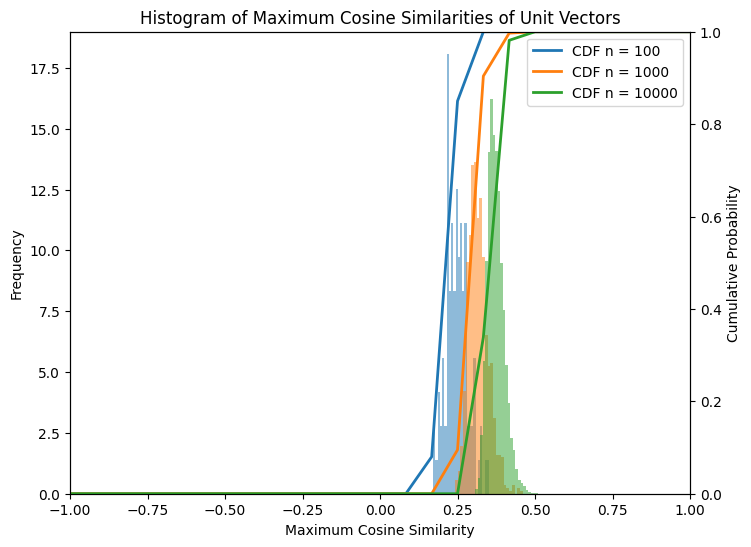

In [ ]:

samples = [100, 1000, 10000]

fig, ax1 = plt.subplots(figsize=(8, 6))
ax2 = ax1.twinx()

for i, n in enumerate(samples):
    max_cos = []
    for re in range(n): 
        random_points = [random_point_on_unit_sphere(100) for _ in range(n)]

        first_item = random_points[0]
        cosine_similarities = []
        for i in range(1, len(random_points)):
            dot_product = np.dot(first_item, random_points[i])
            cosine_similarities.append(dot_product)
        max_cos.append(max(cosine_similarities))

    r = cumfreq(max_cos, numbins=25, defaultreallimits=(-1, 1))
    x = r.lowerlimit + np.linspace(0, r.binsize * r.cumcount.size, r.cumcount.size)
    c = r.cumcount / r.cumcount[-1]

    ax1.hist(max_cos, bins=25, label=f"n = {n}", alpha=0.5, density=True)
    ax2.plot(x, c, label=f"CDF n = {n}", lw=2)
plt.title(f"Histogram of Maximum Cosine Similarities of Unit Vectors")
ax1.set_xlabel("Maximum Cosine Similarity")
ax1.set_ylabel("Frequency")
ax2.set_ylabel("Cumulative Probability")
plt.xlim(-1, 1)
ax2.set_ylim(0, 1)
plt.legend()
plt.show()

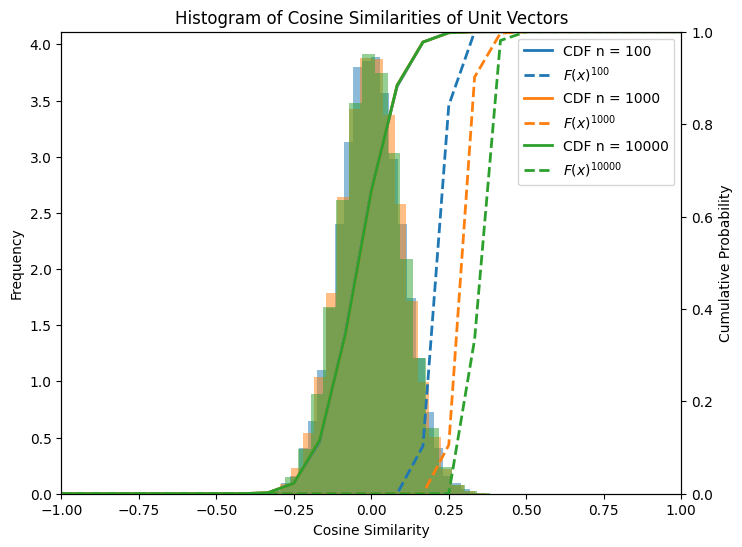

In [ ]:
from scipy.stats import cumfreq
samples = [100, 1000, 10000]

fig, ax1 = plt.subplots(figsize=(8, 6))
ax2 = ax1.twinx()

colors = ['tab:blue', 'tab:orange', 'tab:green']

for color, n in zip(colors, samples):
    cosine_similarities = []
    for re in range(n): 
        random_points = [random_point_on_unit_sphere(100) for _ in range(n)]

        first_item = random_points[re]
        for j in range(1, len(random_points)):
            if j == re:
                continue
            dot_product = np.dot(first_item, random_points[j])
            cosine_similarities.append(dot_product)
        
    r = cumfreq(cosine_similarities, numbins=25, defaultreallimits=(-1, 1))
    x = r.lowerlimit + np.linspace(0, r.binsize * r.cumcount.size, r.cumcount.size)
    cdf = r.cumcount / r.cumcount[-1]
    c = cdf ** n          # added this later after the velocity meeting

    ax1.hist(cosine_similarities, bins=25, label=f"n = {n}", alpha=0.5, density=True, color=color)
    ax2.plot(x, cdf, label=f"CDF n = {n}", lw=2, linestyle='-', color=color)
    ax2.plot(x, c, label=fr"$F(x)^{{{n}}}$", lw=2, linestyle='--', color=color) # also added this later as the plotting of F(x)^n
plt.title("Histogram of Cosine Similarities of Unit Vectors")
ax1.set_xlabel("Cosine Similarity")
ax1.set_ylabel("Frequency")
ax2.set_ylabel("Cumulative Probability")
plt.xlim(-1, 1)
ax2.set_ylim(0, 1)
plt.legend()
plt.show()

I now tried to reconnect my learning to real data and also take the input from the velocity meeting into account

<module 'scanpy' from '/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scanpy/__init__.py'>
Normalized count data: X, spliced, unspliced.
Logarithmized X.
computing neighbors


/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_2265952/142518338.py:42: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


    finished (0:00:15) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 7/28 cores)
or disable the progress bar using `show_progress_bar=False`.

 Gm15949 not recoverable due to insufficient samples.
 not recoverable due to insufficient samples.
    finished (0:00:05) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)


100%|██████████| 36/36 [00:00<00:00, 1638.72it/s]

Normalized count data: X, spliced, unspliced.
Logarithmized X.
computing neighbors


...

Normalized count data: X, spliced, unspliced.
Logarithmized X.
computing neighbors


/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_2265952/142518338.py:42: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 7/28 cores)
    finished (0:00:06) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)


100%|██████████| 1000/1000 [00:01<00:00, 597.18it/s]


[{'Repeat': 0, 'Cells': 36, 'Cosine similarity': array([ 0.31450668,  0.4497582 ,  0.4510025 ,  0.4510025 ,  0.4510025 ,
        0.38048646, -0.09068158,  0.5250287 ,  0.1356767 ,  0.3941981 ,
        0.4510025 ,  0.4510025 ,  0.4510025 ,  0.30386558,  0.2639467 ,
        0.39631453,  0.4510025 ,  0.4510025 ,  0.2639467 ,  0.4510025 ,
        0.4510025 ,  0.4510025 ,  0.4510025 ,  0.4510025 ,  0.2639467 ,
        0.4510025 ,  0.4510025 ,  0.4510025 ,  0.3326587 ,  0.4510025 ,
        0.4510025 ,  0.50776136,  0.4510025 ,  0.1356767 ,  0.2734277 ,
        0.4510025 ], dtype=float32)}, {'Repeat': 0, 'Cells': 500, 'Cosine similarity': array([ 0.54227775,  0.66168076,  0.5348546 ,  0.41491443,  0.4178365 ,
        0.64438015,  0.52704084,  0.8434954 ,  0.4887774 ,  0.45161325,
        0.40992025,  0.35252702,  0.6246732 ,  0.7525458 ,  0.63548195,
        0.5544243 ,  0.62761766,  0.62611794,  0.618327  ,  0.5180466 ,
        0.4757576 ,  0.50259113,  0.45943013,  0.5757414 ,  0.44013786,


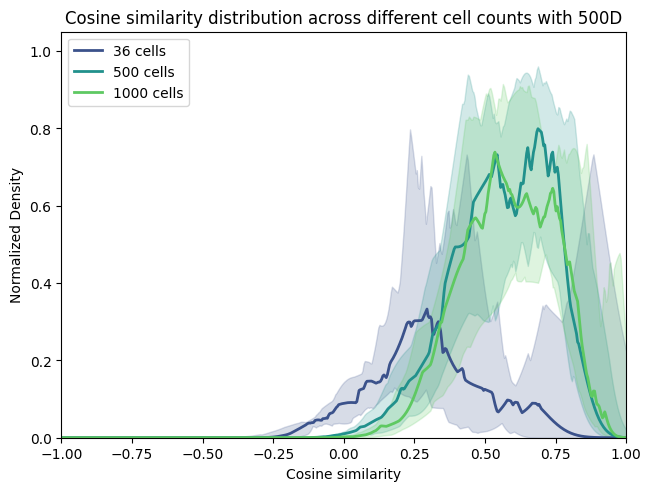

In [ ]:
#This part was run multiple times with changes in dimensions
def calculateBound(adata, k=None, neighbors=True, number_neighbors=200): 
    if neighbors is True:
        nn_indices_optimal = find_neighbors(torch.tensor(adata.layers['Ms']), k_neighbors=number_neighbors)

    maxs = torch.tensor([-2.]*len(adata))
    for i in tqdm(range(len(adata))):
        cos = torch.nn.CosineSimilarity(dim=1, eps=1e-6)
        if neighbors is True:
            expression_all = torch.tensor(adata.layers['Ms'][nn_indices_optimal[i]][:,adata.var.velocity_genes])
        else:
            expression_all = torch.tensor(adata.layers['Ms'][:,adata.var.velocity_genes])
        expression_cell = torch.tensor(adata.layers['Ms'][i,adata.var.velocity_genes]).unsqueeze(0)
        velocity = torch.tensor(adata.layers['velocity'][i,adata.var.velocity_genes]).unsqueeze(0)
        cosines = cos(expression_all - expression_cell, velocity)
        cosines = torch.cat([cosines[:i], cosines[i+1:]])
        if k is None:
            maxs[i] = torch.max(cosines)
        else:
            maxs[i] = torch.mean(torch.topk(cosines, largest=True, k=k).values)

    return maxs

# 0) Rewrite everything an loops for easier computation
number_cells = [36, 500, 1000]
adata_ori = sc.read_h5ad("/mnt/volume/Johanna_Velotest/data/original/pancreas.h5ad")
repeats = 25

save_max_data = []
print(sc)
for run in range(repeats):
    for i, cells in enumerate(number_cells):
        # 1) Create true subsampling sets
        adata = sc.pp.sample(adata_ori, n=cells, axis='obs', copy=True)
        scvelo.pp.filter_and_normalize(adata)
        if adata.n_vars > 500:
            sampled_genes = np.random.choice(adata.var_names, size=500, replace=False)
            adata = adata[:, sampled_genes].copy()
            
        # Optional: Redefine velocity genes explicitly so scvelo knows which to use
        adata.var['velocity_genes'] = True
        scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
        scvelo.tl.recover_dynamics(adata, n_jobs=7)
        scvelo.tl.velocity(adata, mode="dynamical") 

        upper = calculateBound(adata, neighbors=False)
        # Save data
        save_max_data.append({
            "Repeat": run,
            "Cells": cells,
            "Cosine similarity": upper.numpy()
        })
print(save_max_data)
# 4) Plot change in cosine similarity with increasing number of cells
df = pd.DataFrame(save_max_data)

_, ax = plt.subplots(constrained_layout=True)
palette = sns.color_palette("viridis", len(number_cells))
x_grid = np.linspace(-1, 1, 500)

for color, cells in zip(palette, number_cells):
    # Calculate KDE for each repeat
    repeat_kdes = []
    for run in range(repeats):
        values = df.loc[
            (df["Cells"] == cells) &
            (df["Repeat"] == run),
            "Cosine similarity"
        ].iloc[0]

        kde = gaussian_kde(values)
        y = kde(x_grid)
        # Normalize peak to 1
        y /= y.max()
        repeat_kdes.append(y)

    repeat_kdes = np.asarray(repeat_kdes)

    # Median curve
    median = np.median(repeat_kdes, axis=0)
    # Variability band
    q25 = np.percentile(repeat_kdes, 25, axis=0)
    q75 = np.percentile(repeat_kdes, 75, axis=0)

    ax.plot(x_grid,
            median,
            color=color,
            lw=2,
            label=f"{cells} cells")

    ax.fill_between(x_grid,
                    q25,
                    q75,
                    color=color,
                    alpha=0.2)

ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Normalized Density")
ax.legend()
ax.set_xlim(-1,1)
ax.set_ylim(0,1.05)
ax.set_title("Cosine similarity distribution across different cell counts with 500D")
plt.show()


<module 'scanpy' from '/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scanpy/__init__.py'>
Normalized count data: X, spliced, unspliced.
Logarithmized X.
computing neighbors


/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_2316580/3031767077.py:70: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


    finished (0:00:12) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


100%|██████████| 36/36 [00:00<00:00, 1563.53it/s]

Normalized count data: X, spliced, unspliced.
Logarithmized X.


...

    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


100%|██████████| 500/500 [00:00<00:00, 906.34it/s]
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_2316580/3031767077.py:70: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest_a/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


Normalized count data: X, spliced, unspliced.
Logarithmized X.
computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


100%|██████████| 1000/1000 [00:01<00:00, 744.18it/s]


[{'Repeat': 0, 'Cells': 36, 'Cosine similarity': array([ 0.28557104,  0.05837053,  0.06424458,  0.06985766, -0.01280404,
        0.18626976,  0.13844739,  0.11426272, -0.06744872,  0.11437539,
        0.26280838,  0.03456347,  0.23054698,  0.12383015,  0.12274287,
        0.13240494,  0.10302816,  0.05063155,  0.10618968,  0.17075525,
        0.1622064 ,  0.09029015,  0.14247467,  0.12332513,  0.2807178 ,
        0.17295246,  0.16565986,  0.20117442,  0.14027245,  0.0602362 ,
        0.00538811,  0.1824657 ,  0.23027135,  0.10762038,  0.24495678,
        0.19377197], dtype=float32)}, {'Repeat': 0, 'Cells': 500, 'Cosine similarity': array([ 0.23769651,  0.132929  ,  0.10889311,  0.08749817,  0.31112334,
        0.12571546,  0.17443784,  0.1603624 ,  0.1951102 ,  0.261155  ,
        0.28171694,  0.2613566 ,  0.09143256,  0.15808734,  0.12178364,
        0.13740449,  0.19557205,  0.1917595 ,  0.23695607,  0.21120995,
        0.24489154,  0.28986764,  0.23909187,  0.07463683,  0.25314966,


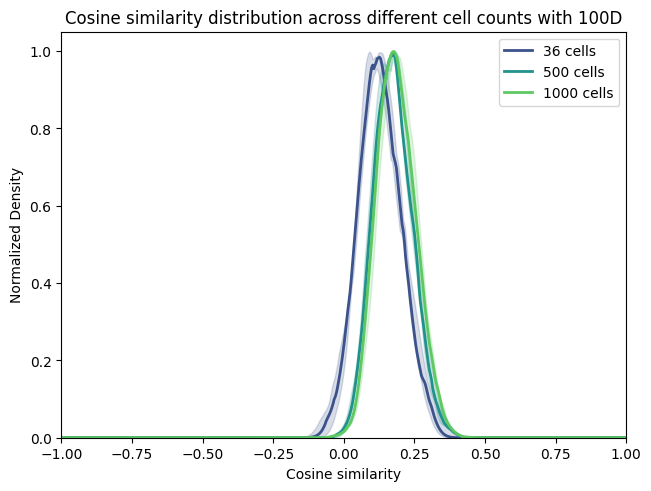

In [3]:
# Simple approach: sample each velocity as a von Mises-drawn angle projected to R^d
#TODO Understand the Code and the von-Mises distribution, this is just a quick AI implemenatation
def sample_vonmises_velocities(n_cells, n_dims, kappa, rng):
    """
    For each cell, sample a random unit mean direction, then
    perturb it by a von Mises-distributed angle and project back.
    """
    # Random mean directions (unit vectors)
    raw = rng.standard_normal((n_cells, n_dims))
    mean_dirs = raw / np.linalg.norm(raw, axis=1, keepdims=True)

    # Von Mises angle perturbation (scalar per cell)
    angles = vonmises.rvs(kappa, size=n_cells)  # angles in [-pi, pi]

    # Build a random orthogonal perturbation direction for each cell
    perturb = rng.standard_normal((n_cells, n_dims))
    # Orthogonalize against mean_dirs
    proj = np.sum(perturb * mean_dirs, axis=1, keepdims=True)
    perturb = perturb - proj * mean_dirs
    perturb = perturb / np.linalg.norm(perturb, axis=1, keepdims=True)

    # Rotate mean_dir by angle toward perturb
    velocities = (np.cos(angles)[:, None] * mean_dirs +
                  np.sin(angles)[:, None] * perturb)
    return velocities

def calculateBound(adata, k=None, neighbors=True, number_neighbors=200): 
    if neighbors is True:
        nn_indices_optimal = find_neighbors(torch.tensor(adata.layers['Ms']), k_neighbors=number_neighbors)

    maxs = torch.tensor([-2.]*len(adata))
    for i in tqdm(range(len(adata))):
        cos = torch.nn.CosineSimilarity(dim=1, eps=1e-6)
        if neighbors is True:
            expression_all = torch.tensor(adata.layers['Ms'][nn_indices_optimal[i]][:,adata.var.velocity_genes])
        else:
            expression_all = torch.tensor(adata.layers['Ms'][:,adata.var.velocity_genes])
        expression_cell = torch.tensor(adata.layers['Ms'][i,adata.var.velocity_genes]).unsqueeze(0)
        velocity = torch.tensor(adata.layers['velocity'][i,adata.var.velocity_genes]).unsqueeze(0)
        cosines = cos(expression_all - expression_cell, velocity)
        cosines = torch.cat([cosines[:i], cosines[i+1:]])
        if k is None:
            maxs[i] = torch.max(cosines)
        else:
            maxs[i] = torch.mean(torch.topk(cosines, largest=True, k=k).values)

    return maxs

# 0) Rewrite everything an loops for easier computation
number_cells = [36, 500, 1000]
adata_ori = sc.read_h5ad("/mnt/volume/Johanna_Velotest/data/original/pancreas.h5ad")
repeats = 10
rng = np.random.default_rng()
dimension = 100
kappa = 10 

save_max_data = []
print(sc)
for run in range(repeats):
    for i, cells in enumerate(number_cells):
        # 1) Create true subsampling sets
        adata = sc.pp.sample(adata_ori, n=cells, axis='obs', copy=True)
        scvelo.pp.filter_and_normalize(adata)
        if adata.n_vars > dimension:
            sampled_genes = np.random.choice(adata.var_names, size=dimension, replace=False)
            adata = adata[:, sampled_genes].copy()
            
        # Optional: Redefine velocity genes explicitly so scvelo knows which to use
        adata.var['velocity_genes'] = True
        scvelo.pp.moments(adata, n_pcs=30, n_neighbors=30)
        adata.layers['velocity'] = sample_vonmises_velocities(cells, dimension, kappa, rng=rng)


        upper = calculateBound(adata, neighbors=False)
        # Save data
        save_max_data.append({
            "Repeat": run,
            "Cells": cells,
            "Cosine similarity": upper.numpy()
        })
print(save_max_data)
# 4) Plot change in cosine similarity with increasing number of cells
df = pd.DataFrame(save_max_data)

_, ax = plt.subplots(constrained_layout=True)
palette = sns.color_palette("viridis", len(number_cells))
x_grid = np.linspace(-1, 1, 500)

for color, cells in zip(palette, number_cells):
    # Calculate KDE for each repeat
    repeat_kdes = []
    for run in range(repeats):
        values = df.loc[
            (df["Cells"] == cells) &
            (df["Repeat"] == run),
            "Cosine similarity"
        ].iloc[0]

        kde = gaussian_kde(values)
        y = kde(x_grid)
        # Normalize peak to 1
        y /= y.max()
        repeat_kdes.append(y)

    repeat_kdes = np.asarray(repeat_kdes)

    # Median curve
    median = np.median(repeat_kdes, axis=0)
    # Variability band
    q25 = np.percentile(repeat_kdes, 25, axis=0)
    q75 = np.percentile(repeat_kdes, 75, axis=0)

    ax.plot(x_grid,
            median,
            color=color,
            lw=2,
            label=f"{cells} cells")

    ax.fill_between(x_grid,
                    q25,
                    q75,
                    color=color,
                    alpha=0.2)

ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Normalized Density")
ax.legend()
ax.set_xlim(-1,1)
ax.set_ylim(0,1.05)
ax.set_title(f"Cosine similarity distribution across different cell counts with {dimension}D")
plt.show()


100%|██████████| 36146/36146 [08:05<00:00, 74.51it/s]


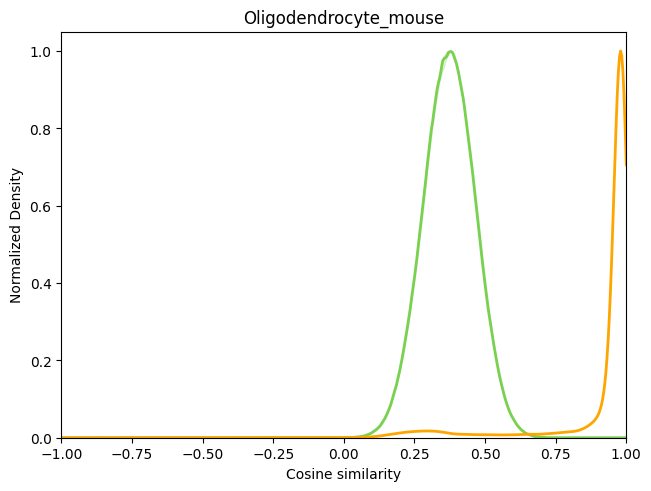

In [ ]:
datasets = {
        #"Spermatogenisis": "../configs/noEmbedding/spermatogenesis.yaml",
        #"Retinal_development": "../configs/retinal_development.yaml",
        #"Human_HSC": "../configs/humanHSC.yaml",
        #"Gastrulation_erythroid": "../configs/gastrulation.yaml",
        #"Pancreas_stochastic": "../configs/pancreas_stochastic.yaml",
        #"PBMC": "../configs/pbmc.yaml",
        "Oligodendrocyte_mouse": "../configs/noEmbedding/oligodendrocyte.yaml",
    }


# Simple approach: sample each velocity as a von Mises-drawn angle projected to R^d
#TODO Understand the Code and the von-Mises distribution, this is just a quick AI implemenatation
def sample_vonmises_velocities(n_cells, n_dims, kappa, rng):
    """
    For each cell, sample a random unit mean direction, then
    perturb it by a von Mises-distributed angle and project back.
    """
    # Random mean directions (unit vectors)
    raw = rng.standard_normal((n_cells, n_dims))
    mean_dirs = raw / np.linalg.norm(raw, axis=1, keepdims=True)

    # Von Mises angle perturbation (scalar per cell)
    angles = vonmises.rvs(kappa, size=n_cells)  # angles in [-pi, pi]

    # Build a random orthogonal perturbation direction for each cell
    perturb = rng.standard_normal((n_cells, n_dims))
    # Orthogonalize against mean_dirs
    proj = np.sum(perturb * mean_dirs, axis=1, keepdims=True)
    perturb = perturb - proj * mean_dirs
    perturb = perturb / np.linalg.norm(perturb, axis=1, keepdims=True)

    # Rotate mean_dir by angle toward perturb
    velocities = (np.cos(angles)[:, None] * mean_dirs +
                  np.sin(angles)[:, None] * perturb)
    return velocities

def calculateBound(adata, k=None, neighbors=True, number_neighbors=200): 
    if neighbors is True:
        nn_indices_optimal = find_neighbors(torch.tensor(adata.layers['Ms']), k_neighbors=number_neighbors)

    maxs = torch.tensor([-2.]*len(adata))
    for i in tqdm(range(len(adata))):
        cos = torch.nn.CosineSimilarity(dim=1, eps=1e-6)
        if neighbors is True:
            expression_all = torch.tensor(adata.layers['Ms'][nn_indices_optimal[i]][:,adata.var.velocity_genes])
        else:
            expression_all = torch.tensor(adata.layers['Ms'][:,adata.var.velocity_genes])
        expression_cell = torch.tensor(adata.layers['Ms'][i,adata.var.velocity_genes]).unsqueeze(0)
        velocity = torch.tensor(adata.layers['velocity'][i,adata.var.velocity_genes]).unsqueeze(0)
        cosines = cos(expression_all - expression_cell, velocity)
        cosines = torch.cat([cosines[:i], cosines[i+1:]])
        if k is None:
            maxs[i] = torch.max(cosines)
        else:
            maxs[i] = torch.mean(torch.topk(cosines, largest=True, k=k).values)

    return maxs


# 0) Rewrite everything an loops for easier computation
for dataset, config in datasets.items():
    with open(config, "r") as f:
            config = yaml.safe_load(f)
    adata = sc.read_h5ad(config["path"])
    number_cells = adata.n_obs
    dimension = np.sum(adata.var.velocity_genes)
    rng = np.random.default_rng()
    repeats = 15
    kappa = 2.0 

    save_max_data = []

    if adata.n_vars > dimension:
        sampled_genes = np.random.choice(adata.var_names, size=dimension, replace=False)
        adata = adata[:, sampled_genes].copy()

    for run in range(repeats):
        adata.layers['velocity'] = sample_vonmises_velocities(number_cells, dimension, kappa=2.0, rng=rng)

        upper = calculateBound(adata, neighbors=False)
        # Save data
        save_max_data.append(upper.numpy())

    # 4) Plot change in cosine similarity with increasing number of cells

    _, ax = plt.subplots(constrained_layout=True)
    palette = sns.color_palette("viridis", 10000)
    x_grid = np.linspace(-1, 1, 500)

    
    # Calculate KDE for each repeat
    repeat_kdes = []
    for values in save_max_data:

        kde = gaussian_kde(values)

        y = kde(x_grid)

        y /= y.max()

        repeat_kdes.append(y)

    repeat_kdes = np.asarray(repeat_kdes)

    # Median curve
    median = np.median(repeat_kdes, axis=0)
    # Variability band
    q25 = np.percentile(repeat_kdes, 25, axis=0)
    q75 = np.percentile(repeat_kdes, 75, axis=0)

    ax.plot(x_grid,
            median,
            color=color,
            lw=2,
            label=f"{number_cells} cells")

    ax.fill_between(x_grid,
                    q25,
                    q75,
                    color=color,
                    alpha=0.2)
    
    # Add upper bound of the real dataset
    bound = adata.obsm['general_bound'] 
    kde = gaussian_kde(bound)
    y = kde(x_grid)
    y /= y.max()

    ax.plot(x_grid, y, color="orange", lw=2, label="Upper bound")
    ax.set_xlabel("Cosine similarity")
    ax.set_ylabel("Normalized Density")
    ax.set_xlim(-1,1)
    ax.set_ylim(0,1.05)
    ax.set_title(dataset)
    plt.show()

